# Chapter 1: Classical Intuition & Repetition Codes

Interactive study workbook implementing and benchmarking classical repetition codes based on [Riverlane Deltakit Chapter 1](https://textbook.riverlane.com/en/latest/notebooks/ch1-intuition/classical-intuition.html).

### Key Concepts Explored:
1. **Majority-Vote Syndrome Decoding:** Correcting independent bit-flip errors.
2. **Exponential Error Suppression:** Comparing code distances $d \in \{1, 3, 5, 7\}$.
3. **The Classical Threshold ($p = 0.5$):** Where repetition coding transitions from error suppression to error amplification.
4. **Correlated Burst Noise Floor:** Modelling correlated errors (cosmic ray analogue).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plotter
from src.repetition_code import (
    encode,
    send,
    receive_and_interpret,
    get_code_error_probability,
    get_code_error_probability_correlated,
)

plotter.rcParams["font.family"] = "Monospace"
print("Modules imported successfully.")

Modules imported successfully.


### 1. Functional Sanity Check
Encoding a bit `1` with distance $d=5$, transmitting through a $10\%$ error channel, and majority decoding.

In [2]:
codeword = encode(1, 5)
noisy_codeword = send(codeword, p_error=0.1)
decoded_bit = receive_and_interpret(noisy_codeword, majority_vote=True)

print(f"Encoded Codeword: {codeword}")
print(f"Received Noisy:   {noisy_codeword}")
print(f"Decoded Message:  {decoded_bit}")

Encoded Codeword: [1, 1, 1, 1, 1]
Received Noisy:   [0, 1, 1, 1, 1]
Decoded Message:  1


### 2. Error Suppression Across Distances
Evaluating logical error rate $P_L$ against physical error rate $p$ on a log-log scale.

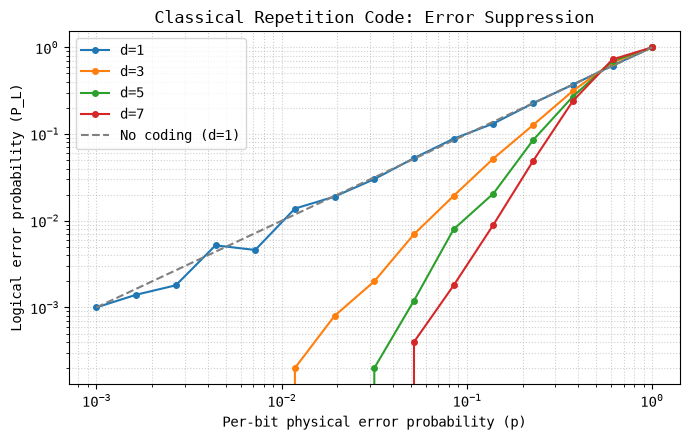

In [3]:
code_distances = [1, 3, 5, 7]
p_errors = np.logspace(-3, 0, 15)
n_shots = 5000

results_iid = {}
for d in code_distances:
    results_iid[d] = [get_code_error_probability(d, p, n_shots=n_shots) for p in p_errors]

plotter.figure(figsize=(7, 4.5))
for d in code_distances:
    plotter.loglog(p_errors, results_iid[d], marker=".", markersize=8, label=f"d={d}")
plotter.plot(p_errors, p_errors, linestyle="--", color="gray", label="No coding (d=1)")
plotter.xlabel("Per-bit physical error probability (p)")
plotter.ylabel("Logical error probability (P_L)")
plotter.title("Classical Repetition Code: Error Suppression")
plotter.grid(True, which="both", linestyle=":", alpha=0.6)
plotter.legend()
plotter.tight_layout()
plotter.show()

### 3. The Error Correction Threshold ($p = 0.5$)
When $p < 0.5$, increasing $d$ suppresses errors. When $p > 0.5$, adding bits increases the chance of failure.

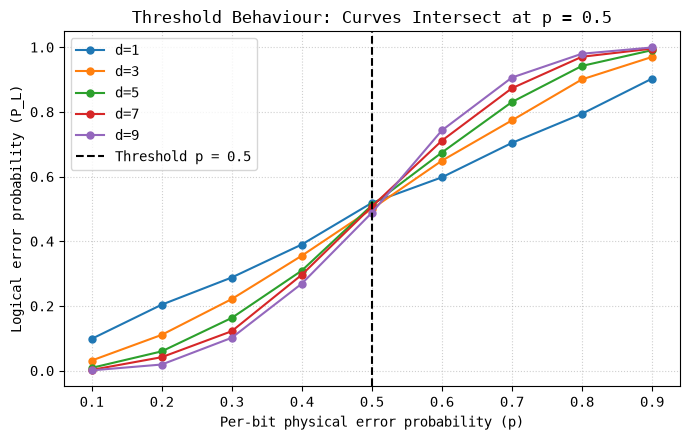

In [4]:
p_linear = np.linspace(0.1, 0.9, 9)
threshold_distances = [1, 3, 5, 7, 9]

results_threshold = {
    d: [get_code_error_probability(d, p, n_shots=3000) for p in p_linear]
    for d in threshold_distances
}

plotter.figure(figsize=(7, 4.5))
for d in threshold_distances:
    plotter.plot(p_linear, results_threshold[d], marker="o", markersize=5, label=f"d={d}")
plotter.axvline(0.5, color="black", linestyle="--", label="Threshold p = 0.5")
plotter.xlabel("Per-bit physical error probability (p)")
plotter.ylabel("Logical error probability (P_L)")
plotter.title("Threshold Behaviour: Curves Intersect at p = 0.5")
plotter.grid(True, linestyle=":", alpha=0.6)
plotter.legend()
plotter.tight_layout()
plotter.show()

### 4. Impact of Correlated Noise (Error Bursts)
Even a tiny probability of global bit-flip bursts creates an uncorrectable logical error floor.

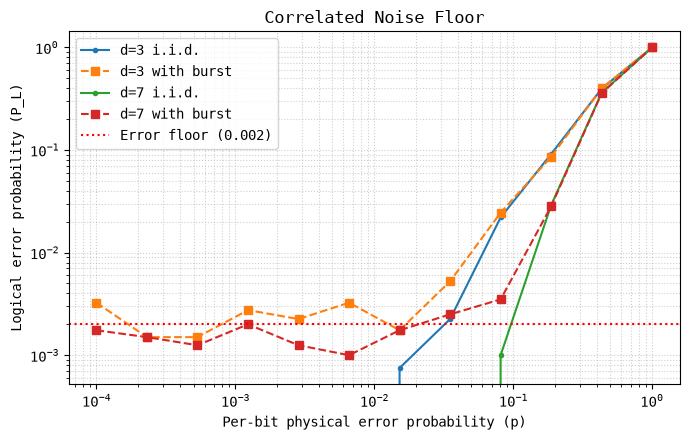

In [5]:
p_burst = np.logspace(-4, 0, 12)
p_corr_val = 2e-3
d_test = [3, 7]

plotter.figure(figsize=(7, 4.5))
for d in d_test:
    err_iid = [get_code_error_probability(d, p, n_shots=4000) for p in p_burst]
    err_corr = [get_code_error_probability_correlated(d, p, p_corr_val, n_shots=4000) for p in p_burst]
    plotter.loglog(p_burst, err_iid, linestyle="-", marker=".", label=f"d={d} i.i.d.")
    plotter.loglog(p_burst, err_corr, linestyle="--", marker="s", label=f"d={d} with burst")

plotter.axhline(p_corr_val, color="red", linestyle=":", label=f"Error floor ({p_corr_val})")
plotter.xlabel("Per-bit physical error probability (p)")
plotter.ylabel("Logical error probability (P_L)")
plotter.title("Correlated Noise Floor")
plotter.grid(True, which="both", linestyle=":", alpha=0.6)
plotter.legend()
plotter.tight_layout()
plotter.show()